# Partie 2. Lois usuelles, couples de variables, théorèmes limites

Reconnaître et manipuler les lois usuelles, mesurer la dépendance, et voir la mutualisation à l'oeuvre.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Chapitre 5. Lois discrètes : binomiale ou Poisson ?

P(N=0)  : 0.0022612410099957787 0.0024787521766663585
P(N<=3) : 0.14715119408240107 0.15120388277664784
P(N>=10): 0.08077935912760692 0.08392401699487584


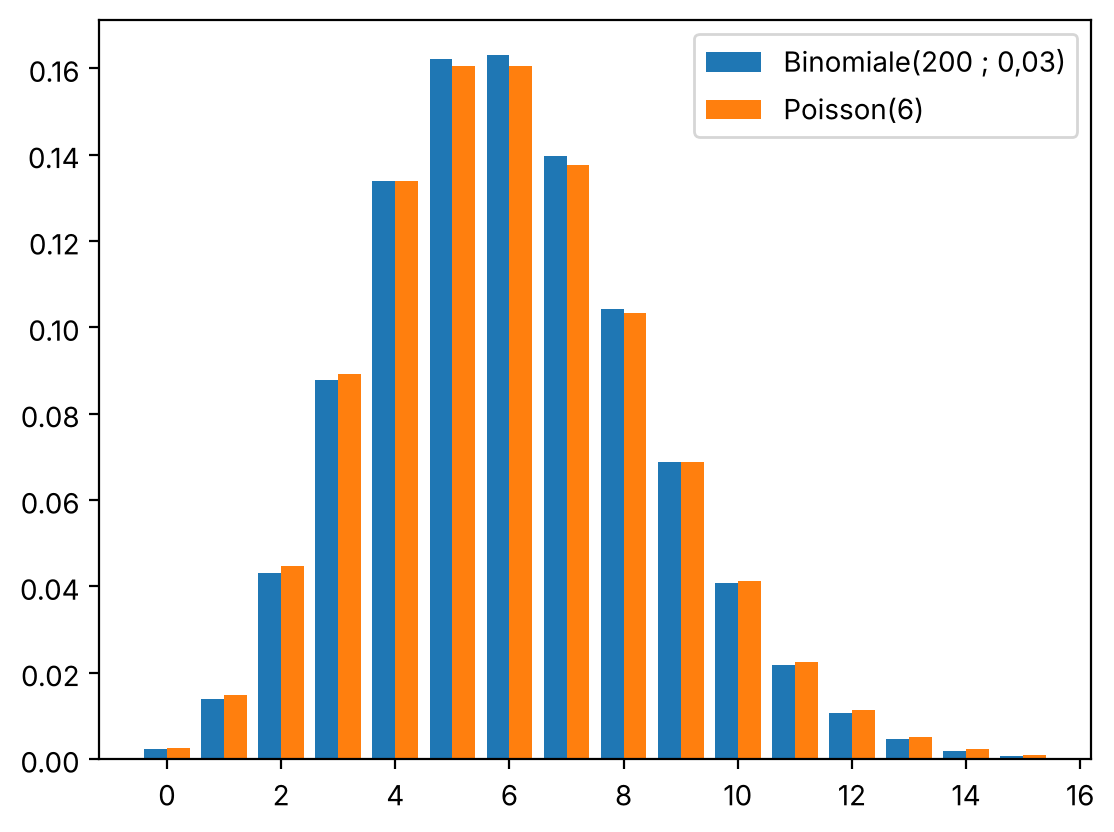

In [2]:
B, P = stats.binom(200, 0.03), stats.poisson(6)
print('P(N=0)  :', B.pmf(0), P.pmf(0))
print('P(N<=3) :', B.cdf(3), P.cdf(3))
print('P(N>=10):', B.sf(9), P.sf(9))
k = np.arange(0, 16)
plt.bar(k - 0.2, B.pmf(k), width=0.4, label='Binomiale(200 ; 0,03)')
plt.bar(k + 0.2, P.pmf(k), width=0.4, label='Poisson(6)'); plt.legend(); plt.show()

### Surdispersion : Poisson contre binomiale négative de même moyenne

In [3]:
r, p = 3, 3/(3+6)            # binomiale negative de moyenne r(1-p)/p = 6
NB = stats.nbinom(r, p)
print('Moyennes :', P.mean(), NB.mean(), '| Variances :', P.var(), NB.var())
print('P(N >= 15) : Poisson', P.sf(14), '| Binomiale negative', NB.sf(14))

Moyennes : 6.0 6.0 | Variances : 6.0 18.0
P(N >= 15) : Poisson 0.0014003538333618914 | Binomiale negative 0.04415072637007597


## Chapitre 5. Lois continues

In [4]:
R = stats.norm(0.01, 0.05); print('P(R < -5 %) =', R.cdf(-0.05))
L = stats.lognorm(s=1, scale=np.exp(6)); print('Lognormale : mediane', L.median(), 'moyenne', L.mean())
G = stats.gamma(a=2, scale=500); print('Gamma(2,500) :', G.mean(), G.var(), G.ppf(0.99))

P(R < -5 %) = 0.11506967022170822
Lognormale : mediane 403.4287934927351 moyenne 665.1416330443618
Gamma(2,500) : 1000.0 500000.0 3319.1760339969055


### Comparer les queues de quatre lois de moyenne 1

exponentielle   moyenne=1.00 ['6.7e-03', '4.5e-05', '2.1e-09', '1.9e-22']
lognormale      moyenne=1.00 ['1.7e-02', '2.5e-03', '2.4e-04', '5.1e-06']
Pareto a=2.5    moyenne=1.00 ['5.0e-03', '8.8e-04', '1.6e-04', '1.6e-05']
Weibull k=0.5   moyenne=1.00 ['4.2e-02', '1.1e-02', '1.8e-03', '4.5e-05']


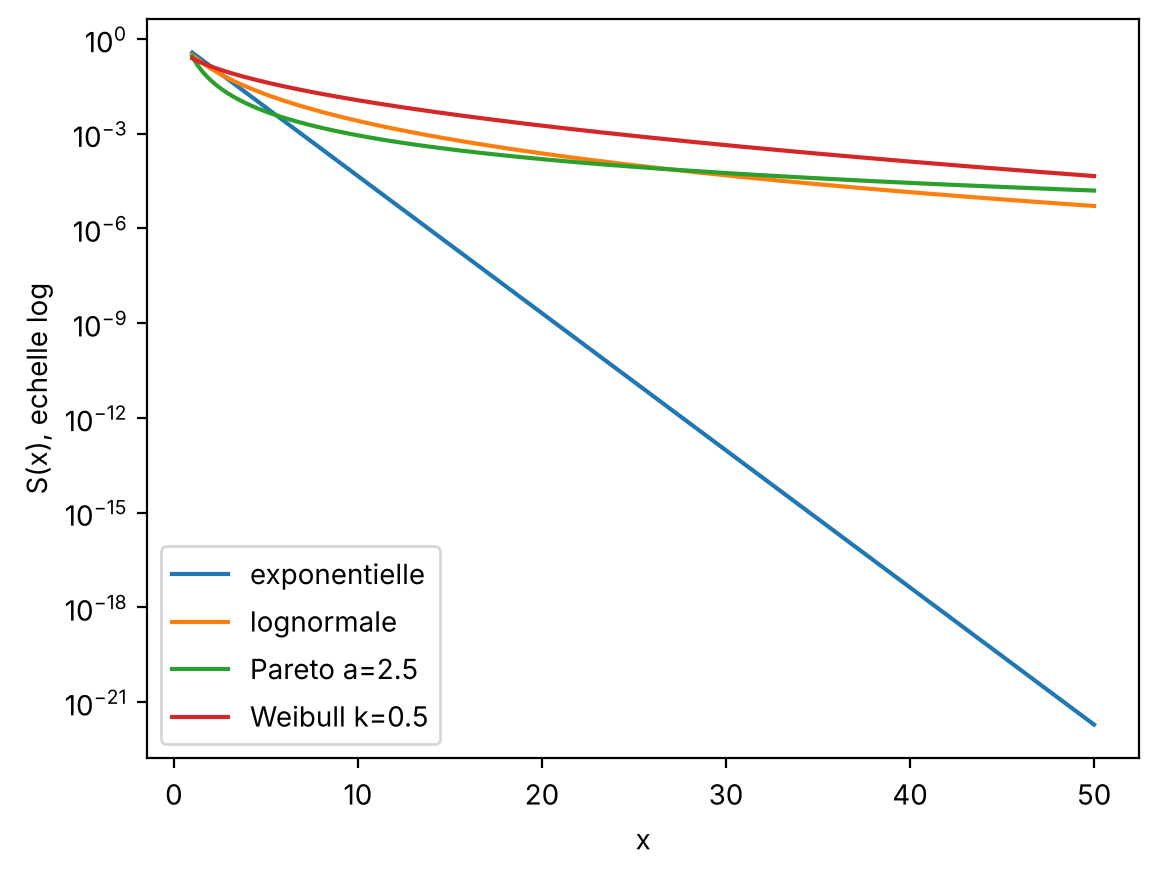

In [5]:
lois = {'exponentielle': stats.expon(), 'lognormale': stats.lognorm(s=1, scale=np.exp(-0.5)),
        'Pareto a=2.5': stats.pareto(b=2.5, scale=0.6), 'Weibull k=0.5': stats.weibull_min(c=0.5, scale=0.5)}
xs = np.linspace(1, 50, 400)
for nom, loi in lois.items():
    print(f'{nom:15s} moyenne={loi.mean():.2f}', ['%.1e' % loi.sf(x) for x in [5, 10, 20, 50]])
    plt.semilogy(xs, loi.sf(xs), label=nom)
plt.xlabel('x'); plt.ylabel('S(x), echelle log'); plt.legend(); plt.show()

### [N3] Fonction d'excès moyen estimée sur données simulées

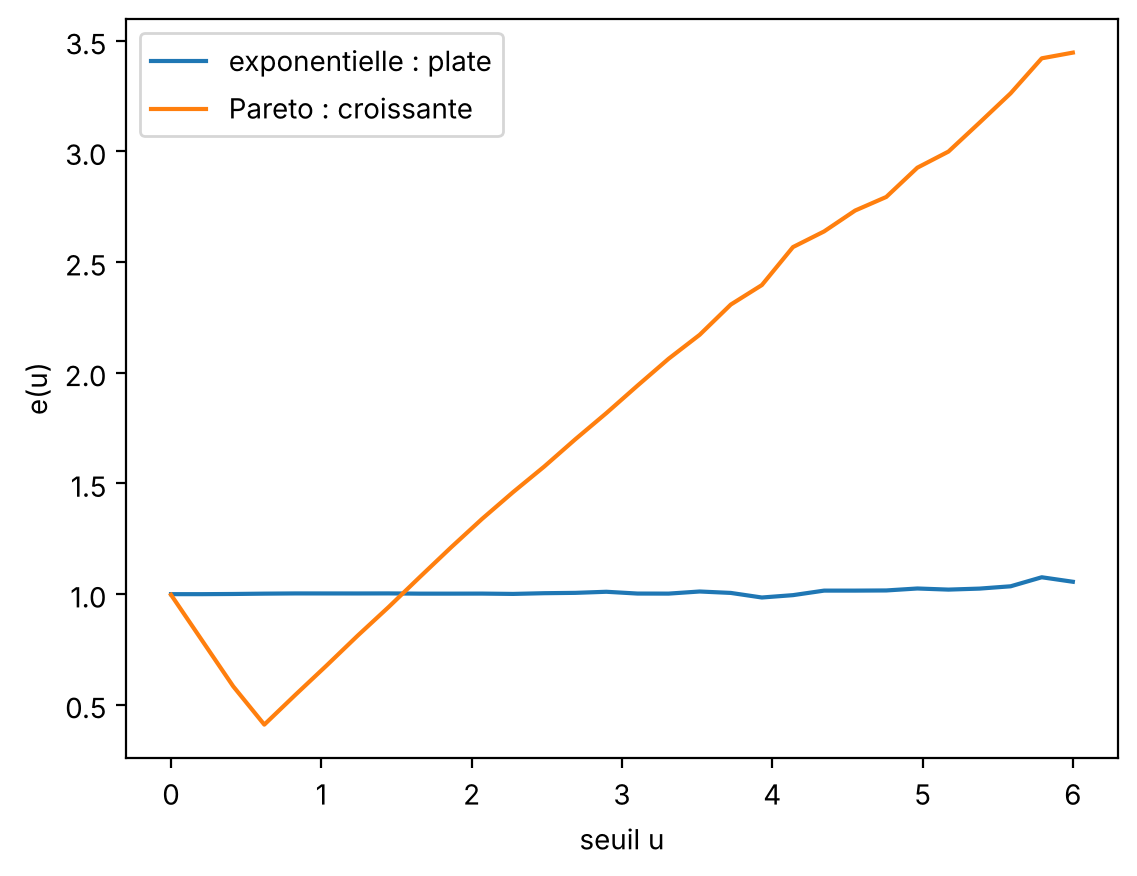

In [6]:
def exces_moyen(x, seuils):
    return [np.mean(x[x > u] - u) for u in seuils]
seuils = np.linspace(0, 6, 30)
xe = stats.expon().rvs(200_000, random_state=rng)
xp = stats.pareto(b=2.5, scale=0.6).rvs(200_000, random_state=rng)
plt.plot(seuils, exces_moyen(xe, seuils), label='exponentielle : plate')
plt.plot(seuils, exces_moyen(xp, seuils), label='Pareto : croissante')
plt.xlabel('seuil u'); plt.ylabel('e(u)'); plt.legend(); plt.show()

## Chapitre 6. Couple auto / habitation

In [7]:
J = np.array([[0.60, 0.10], [0.15, 0.08], [0.03, 0.04]])
a, h = np.array([0, 1, 2]), np.array([0, 1])
pA, pH = J.sum(axis=1), J.sum(axis=0)
print('Marginales :', pA, pH, '| independants ?', np.allclose(J, np.outer(pA, pH)))
EA, EH = a @ pA, h @ pH; EAH = a @ J @ h
VA, VH = a**2 @ pA - EA**2, h**2 @ pH - EH**2
cov = EAH - EA*EH
print('Cov =', cov, '| rho =', cov/np.sqrt(VA*VH), '| Var(A+H) =', VA + VH + 2*cov, 'vs', VA + VH, 'si independants')
print('P(H=1 | A=2) =', J[2, 1]/pA[2], '| P(H=1 | A=0) =', J[0, 1]/pA[0])

Marginales : [0.7  0.23 0.07] [0.78 0.22] | independants ? False
Cov = 0.0786 | rho = 0.3106356384441595 | Var(A+H) = 0.7019 vs 0.5447 si independants
P(H=1 | A=2) = 0.5714285714285714 | P(H=1 | A=0) = 0.14285714285714288


### Portefeuille de deux actifs : l'écart-type selon le poids

w = 0.6 : 0.1338656042454521 | w* = 0.14285714285714285 | sigma min = 0.09562008157285792


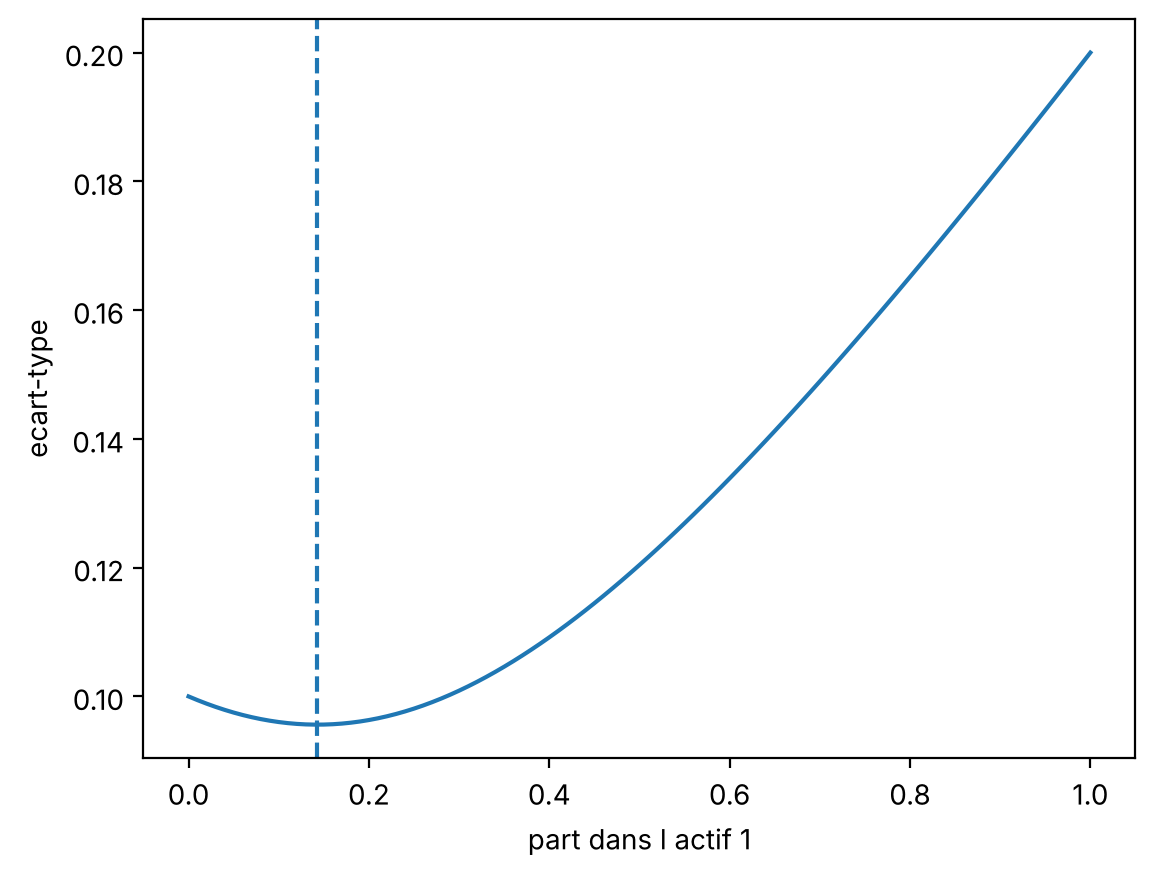

In [8]:
s1, s2, r = 0.20, 0.10, 0.2
w = np.linspace(0, 1, 101)
sp_ = np.sqrt(w**2*s1**2 + (1-w)**2*s2**2 + 2*w*(1-w)*r*s1*s2)
wstar = (s2**2 - r*s1*s2) / (s1**2 + s2**2 - 2*r*s1*s2)
print('w = 0.6 :', np.sqrt(0.36*s1**2 + 0.16*s2**2 + 2*0.24*r*s1*s2), '| w* =', wstar, '| sigma min =', sp_.min())
plt.plot(w, sp_); plt.axvline(wstar, ls='--'); plt.xlabel('part dans l actif 1'); plt.ylabel('ecart-type'); plt.show()

## Chapitre 7. Loi des grands nombres

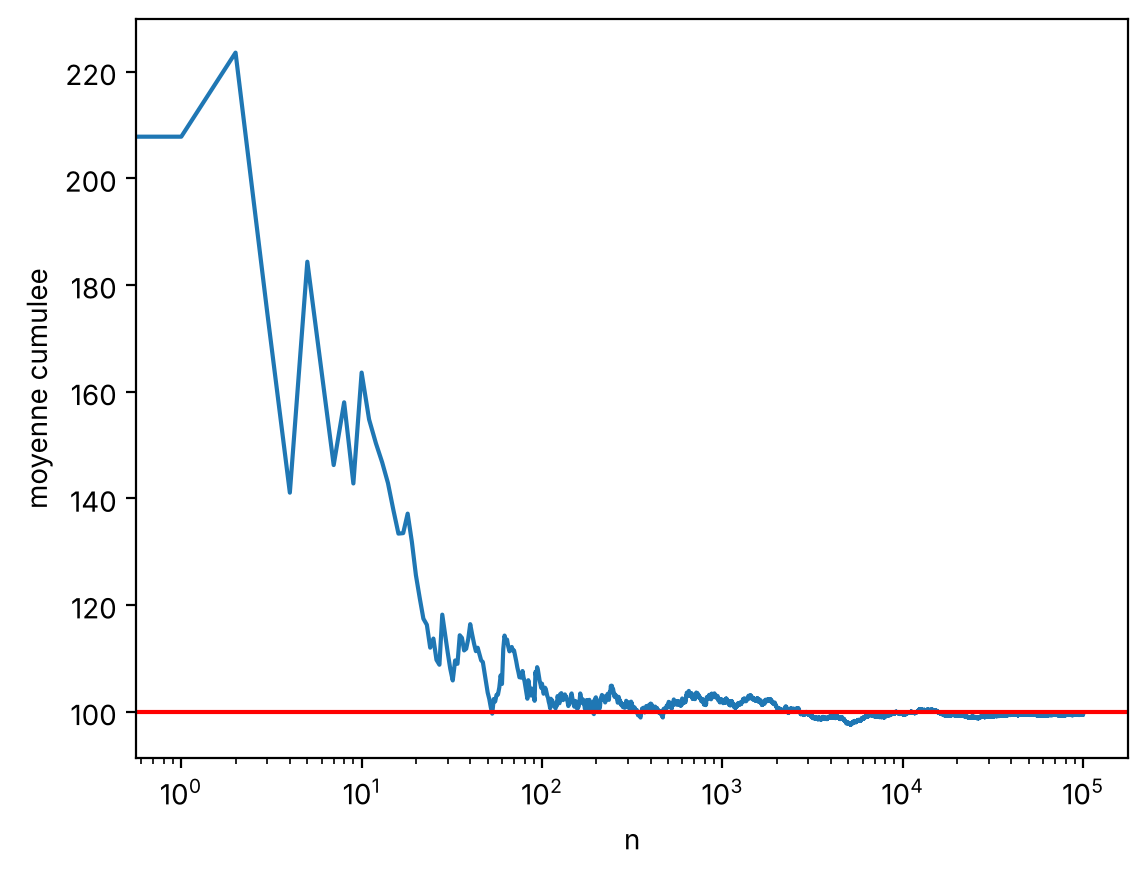

In [9]:
x = rng.exponential(100, size=100_000)
moy = np.cumsum(x) / np.arange(1, len(x) + 1)
plt.plot(moy); plt.axhline(100, color='red'); plt.xscale('log'); plt.xlabel('n'); plt.ylabel('moyenne cumulee'); plt.show()

## Théorème central limite

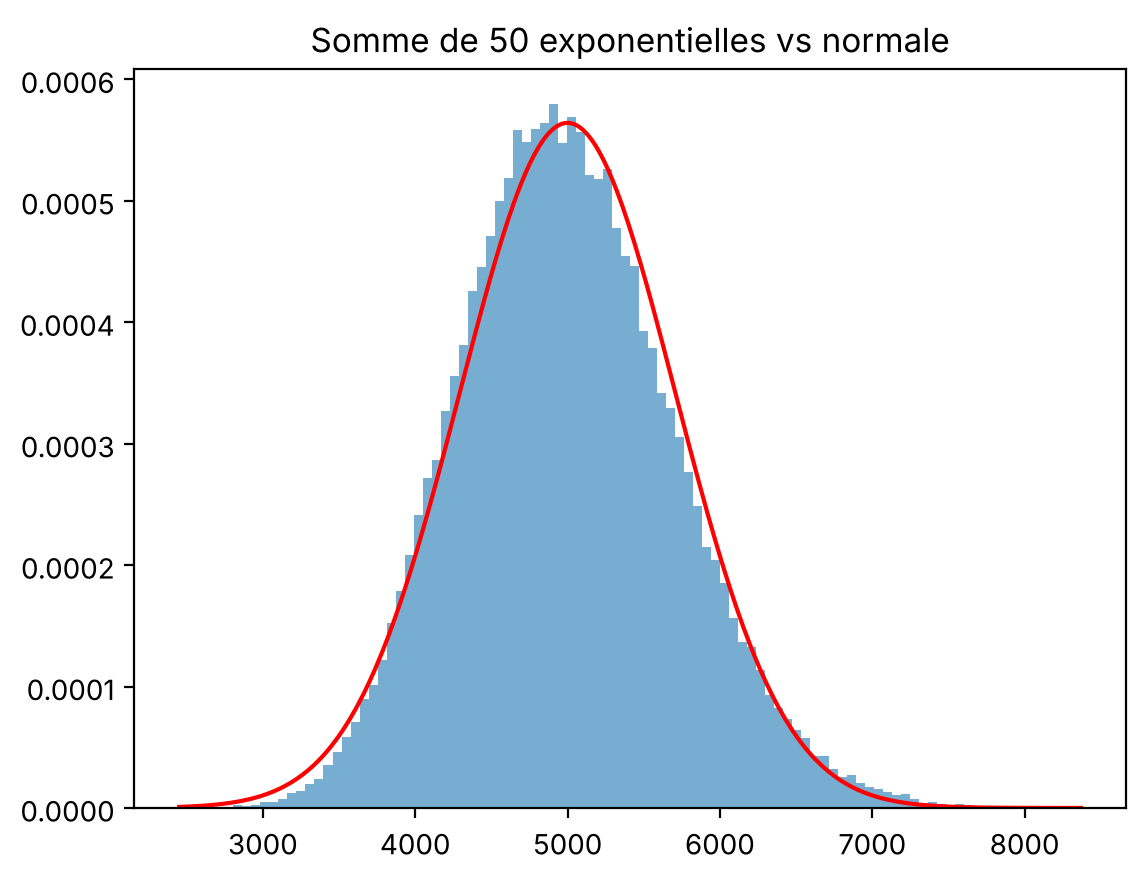

In [10]:
S = rng.exponential(100, size=(100_000, 50)).sum(axis=1)
plt.hist(S, bins=100, density=True, alpha=0.6)
z = np.linspace(S.min(), S.max(), 300)
plt.plot(z, stats.norm(5000, 100*np.sqrt(50)).pdf(z), 'r'); plt.title('Somme de 50 exponentielles vs normale'); plt.show()

## Mutualisation : chargement par contrat selon la taille du portefeuille

In [11]:
for n in [100, 1_000, 10_000, 100_000]:
    print(f'n={n:>7}  CV={3/np.sqrt(n):.3f}  chargement={stats.norm.ppf(0.99)*300*np.sqrt(n)/n:.2f}')
sigS = 300*np.sqrt(1000)
print('P(S > 105 000) avec n=1000 :', stats.norm.sf(5000/sigS))

n=    100  CV=0.300  chargement=69.79
n=   1000  CV=0.095  chargement=22.07
n=  10000  CV=0.030  chargement=6.98
n= 100000  CV=0.009  chargement=2.21
P(S > 105 000) avec n=1000 : 0.2990807263417641


## Vérification des exercices 5.1 à 7.4

In [12]:
B = stats.binom(50, .04); print('5.1 :', B.pmf(0), B.cdf(2), B.mean(), B.var())
P4 = stats.poisson(4); print('5.2 :', P4.pmf(0), P4.pmf(4), P4.sf(5))
print('5.3 :', stats.binom(1000, .002).cdf(1), stats.poisson(2).cdf(1))
print('5.4 :', stats.norm(.01, .05).cdf(-.05), -.01 + .05*stats.norm.ppf(.99))
L = stats.lognorm(s=1, scale=np.exp(6)); print('5.5 :', L.median(), L.mean(), L.sf(2000))
Pa = stats.pareto(b=2.5, scale=10)
print('5.6 :', Pa.mean(), Pa.var(), Pa.sf(50), 50/1.5, Pa.expect(lambda x: max(x - 50, 0)))
sim = Pa.rvs(2_000_000, random_state=rng); print('5.6 simulation :', np.maximum(sim - 50, 0).mean())

print('6.1 :', 0.1 - 0.3*0.3, (0.1 - 0.09)/0.21)
print('6.2 :', 4*4 + 9*9 - 2*2*3*1)
xv = np.array([-1, 0, 1]); print('6.3 : Cov =', np.mean(xv * xv**2) - np.mean(xv)*np.mean(xv**2), '| P(X=0,Y=0)=1/3 vs', 1/9)
print('6.4 : w* =', wstar, '| sigma =', np.sqrt(wstar**2*s1**2 + (1-wstar)**2*s2**2 + 2*wstar*(1-wstar)*r*s1*s2))
print('6.5 :', np.exp(-5), stats.poisson(5).sf(7), stats.binom(5, .6).pmf(3))
n1 = rng.poisson(3, 2_000_000); n2 = rng.poisson(2, 2_000_000); garde = (n1 + n2) == 5
print('6.5 simulation : P(N1=3 | N=5) ~', np.mean(n1[garde] == 3))

print('7.1 :', 100/np.sqrt(400), 25/100, 2*stats.norm.sf(2))
B = stats.binom(1000, .05); s = B.std()
print('7.2 :', stats.norm.sf(10/s), stats.norm.sf(9.5/s), B.sf(59))
z = stats.norm.ppf(.995)
print('7.3 :', 2500*200, 600*50, 200 + z*600*50/2500, 200 + z*600*100/10000)

5.1 : 0.1298857935220386 0.6767140040965933 2.0 1.92
5.2 : 0.01831563888873418 0.19536681481316454 0.2148696129695948
5.3 : 0.4057349081113795 0.40600584970983794
5.4 : 0.11506967022170822 0.10631739370204205
5.5 : 403.4287934927351 665.1416330443618 0.05469926238277735
5.6 : 16.666666666666668 222.22222222222223 0.01788854381999832 33.333333333333336 0.5962847939717895
5.6 simulation : 0.5836732963397454
6.1 : 0.010000000000000009 0.047619047619047665
6.2 : 85
6.3 : Cov = 0.0 | P(X=0,Y=0)=1/3 vs 0.1111111111111111
6.4 : w* = 0.14285714285714285 | sigma = 0.0956182887467515
6.5 : 0.006737946999085467 0.13337167407000744 0.3455999999999997


6.5 simulation : P(N1=3 | N=5) ~ 0.34523606370876
7.1 : 5.0 0.25 0.04550026389635839
7.2 : 0.0733965436542855 0.08403915951748514 0.08673217838486103
7.3 : 500000 30000 230.9099516425868 215.4549758212934


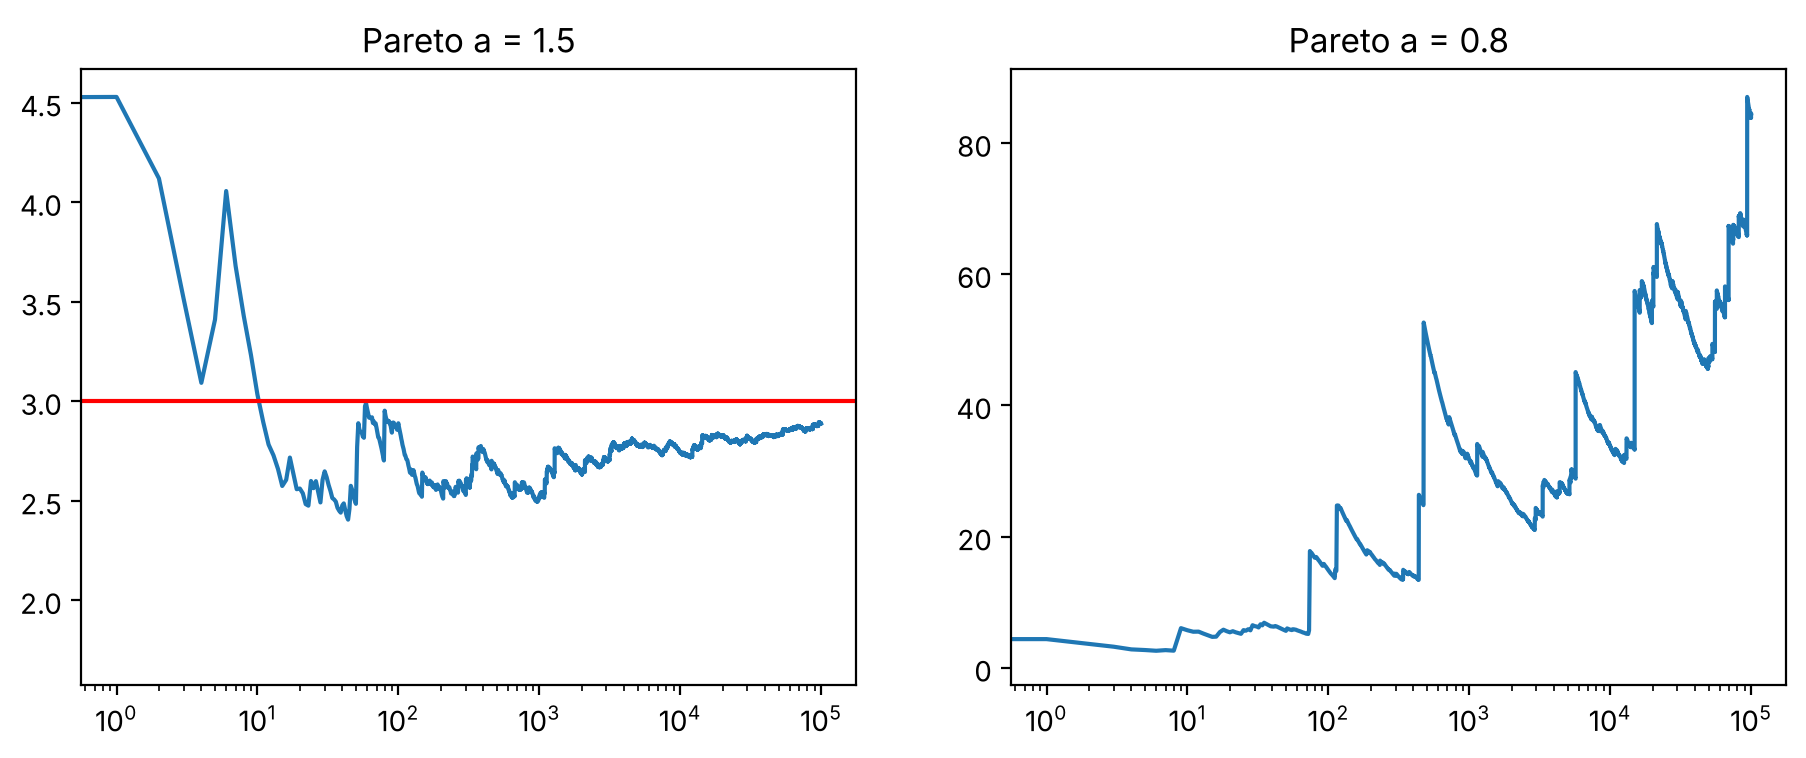

In [13]:
# 7.4 : Pareto a variance infinie (a = 1.5) puis a moyenne infinie (a = 0.8)
for a_, ax in zip([1.5, 0.8], plt.subplots(1, 2, figsize=(11, 4))[1]):
    x = stats.pareto(b=a_, scale=1).rvs(100_000, random_state=rng)
    ax.plot(np.cumsum(x) / np.arange(1, len(x) + 1)); ax.set_xscale('log'); ax.set_title(f'Pareto a = {a_}')
    if a_ > 1: ax.axhline(a_/(a_ - 1), color='red')
plt.show()